In [1]:
%matplotlib inline
import numpy as np
import cv2
import matplotlib.pyplot as plt

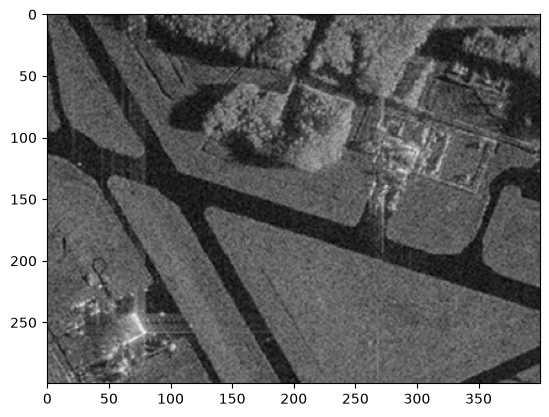

In [2]:
# 1. Выделение участка газона
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

In [3]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False


In [4]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        #print(count)
        mask += local_mask

    return mask*255

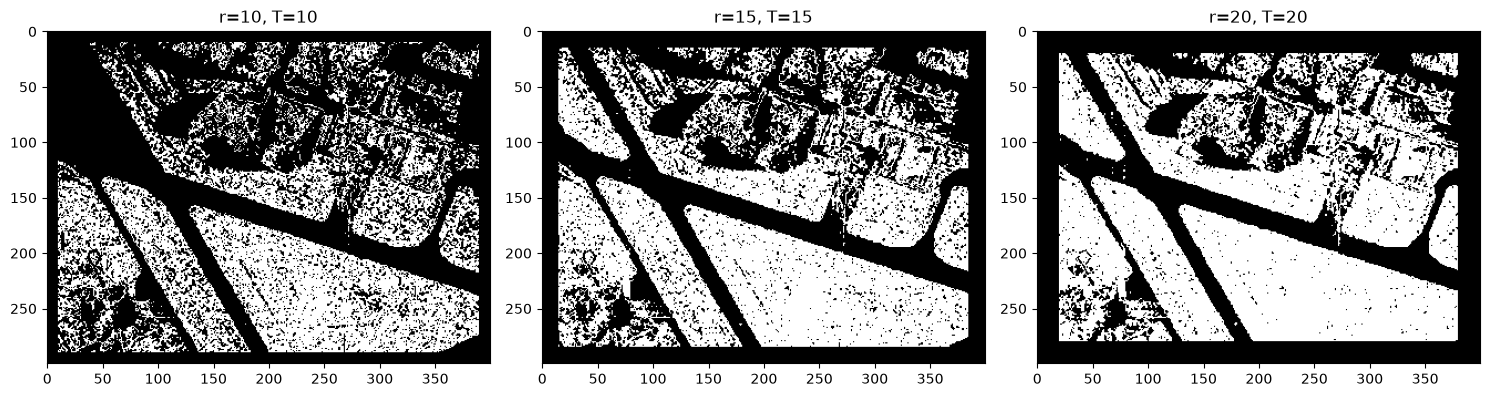

In [5]:
seed_point = (250,250)
#подбор
fig, axes = plt.subplots(1, 3, figsize=(15, 8))
params = [(10, 10), (15, 15), (20, 20)]

for ax, (r, T) in zip(axes.flat, params):
    mask = region_growing(image_gray, seed_point, homo_average, r, T)
    ax.imshow(mask, cmap="gray")
    ax.set_title(f"r={r}, T={T}")

plt.tight_layout()
plt.show()

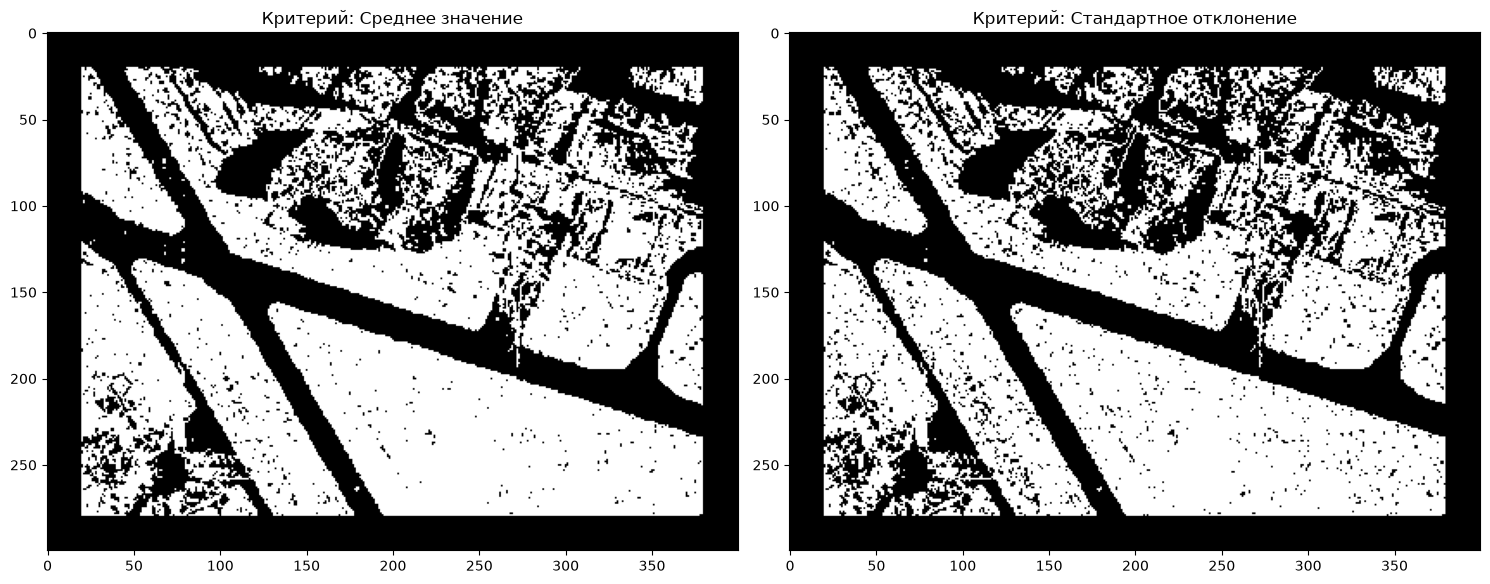

In [11]:
# 2. Вычисление критерия однородности, отличного от представленного
# критерий на основе среднего значения
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    return abs(av_val - img[point]) <= T

# критерий на основе стандартного отклонения
def std_dev_homogeneity(img, mask, point, T, T_min=15):
    region_pixels = img[mask > 0]
    mean = np.mean(region_pixels)
    std_dev = np.std(region_pixels)
    threshold = max(T * std_dev, T_min)
    return abs(mean - img[point]) <= threshold

def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i - r:i + r, j - r:j + r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask * 255

seed_point = (250, 250)
r = 20

mask_avg = region_growing(image_gray, seed_point, homo_average, r, T=20)
mask_std = region_growing(image_gray, seed_point, std_dev_homogeneity, r, T=2) 

# визуализация для сравнения
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(mask_avg, cmap="gray")
axes[0].set_title("Критерий: Среднее значение")

axes[1].imshow(mask_std, cmap="gray")
axes[1].set_title("Критерий: Стандартное отклонение")

plt.tight_layout()
plt.show()

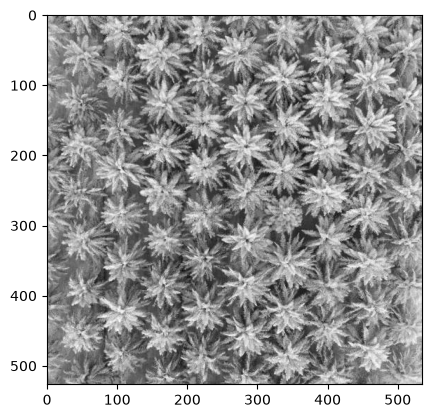

In [32]:
# 3. Алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.
palm = cv2.imread('palm_1.jpg')
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
plt.imshow(palm_gray, cmap="gray")

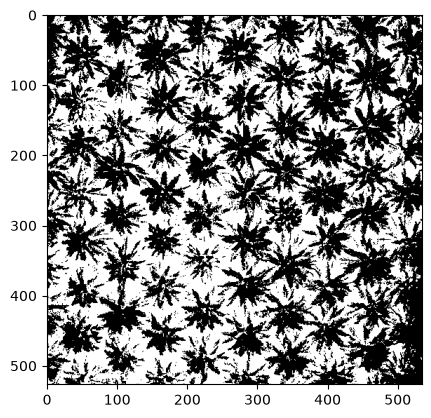

In [33]:
ret, thresh_sar = cv2.threshold(palm_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
plt.imshow(thresh_sar, cmap="gray")

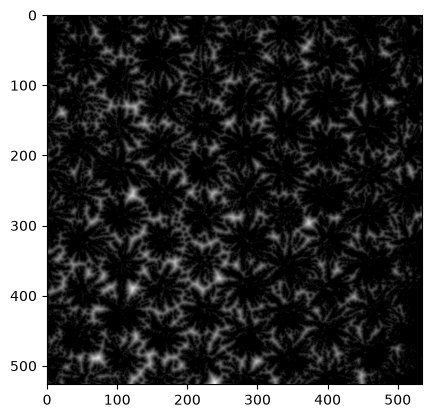

In [34]:
dist_sar = cv2.distanceTransform(thresh_sar, cv2.DIST_L2, 5)
plt.imshow(dist_sar, cmap="gray")

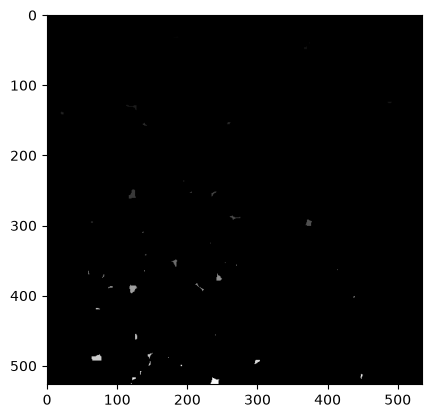

In [35]:
sure_fg_sar = sure_fg_sar.astype(np.uint8)
ret, markers_sar = cv2.connectedComponents(sure_fg_sar)
plt.imshow(markers_sar, cmap="gray")

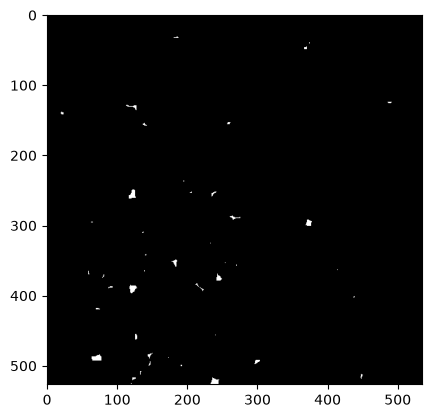

In [36]:
ret, sure_fg_sar = cv2.threshold(dist_sar, 0.6 * dist_sar.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg_sar, cmap="gray")

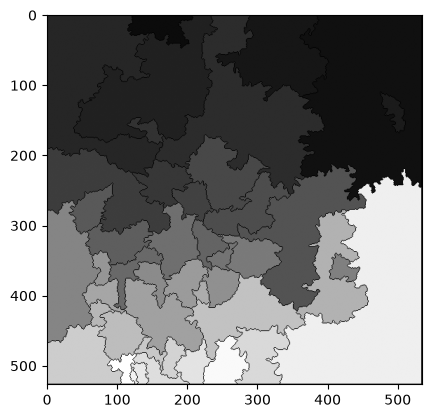

In [37]:
markers_sar = cv2.watershed(palm, markers_sar)
plt.imshow(markers_sar, cmap="gray")

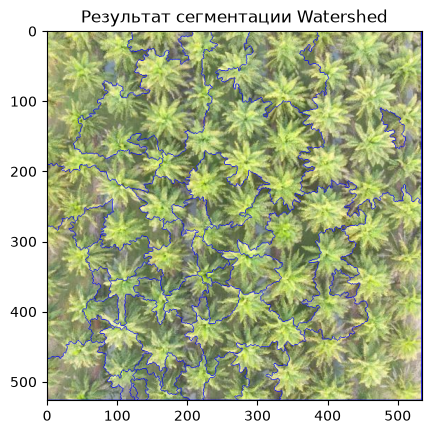

Обнаружено пальмовых деревьев (сегментов): 45


In [38]:
# визуализация результата
image_with_boundaries = palm.copy()
image_with_boundaries[markers_sar == -1] = [255, 0, 0]
plt.imshow(cv2.cvtColor(image_with_boundaries, cv2.COLOR_BGR2RGB))
plt.title("Результат сегментации Watershed")
plt.show()

unique_labels = np.unique(markers_sar)
tree_labels = unique_labels[(unique_labels != 0) & (unique_labels != -1)]
num_trees = len(tree_labels)

print(f"Обнаружено пальмовых деревьев (сегментов): {num_trees}")